
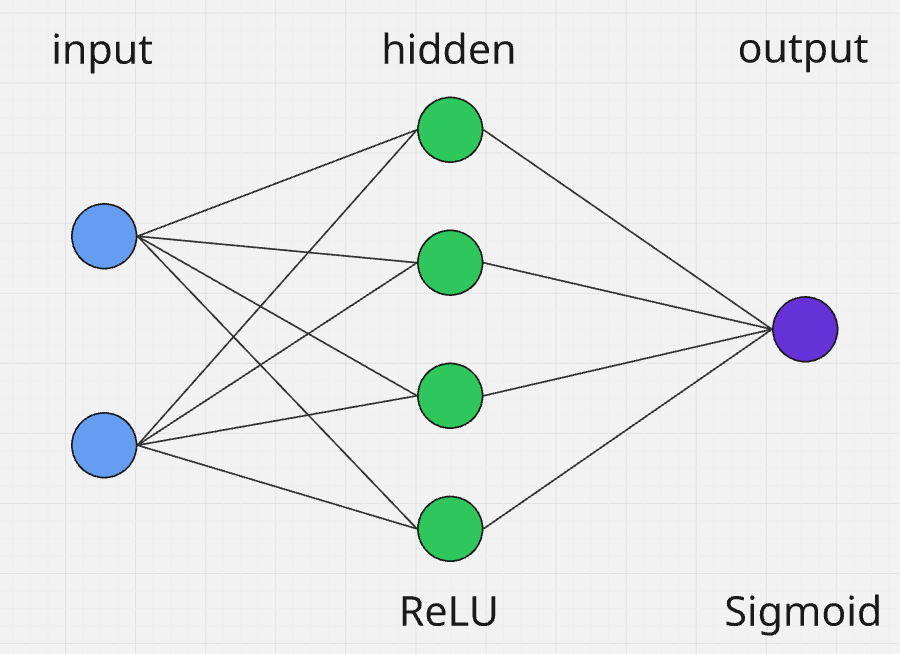

In [41]:
import numpy as np
import matplotlib.pyplot as plt

- Схема обучения нейронки:
    - Forward Propagation - вычислить предсказание
    - Loss function - вычислить ошибку
    - Backward Propagation - Найти градиенты (веса которые ошиблись)
    - Gradient Descent - обновить веса
    - Повторить много раз

In [42]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_grad(a):
    return a * (1 - a)

def relu(z):
    return np.maximum(0, z)

def relu_grad(z):
    return (z>0).astype(float)

In [43]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

### HE
$$
W \sim N(0, \sqrt{\frac{2}{n}})
$$

In [44]:
np.random.seed(42)
hidden_size = 4
# HE initialization - W ~ N(0, sqrt(2/n))

W1 = np.random.randn(2, hidden_size) * np.sqrt(2.0/2)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, 1) * np.sqrt(2.0/hidden_size)
b2 = np.zeros((1, 1))

lr = 0.1

In [45]:
def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)
    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)
    return Z1, A1, Z2, A2

In [46]:
def backward(X, y, Z1, A1, A2, W2):
    m = len(X)

    dZ2 = A2 - y
    dW2 = A1.T @ dZ2 / m
    db2 = np.sum(dZ2, axis=0, keepdims=True)/m

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * relu_grad(Z1)
    dW1 = X.T @ dZ1 / m
    db1 = np.sum(dZ1, axis=0, keepdims=True)/m

    return dW1, db1, dW2, db2

In [47]:
losses = []

for epoch in range(6000):
    Z1, A1, Z2, A2 = forward(X, W1, b1, W2, b2)
    # BCE (Binary-Cross Entropy)
    loss = -np.mean(y*np.log(A2+1e-8) + (1-y)*np.log(1-A2 + 1e-8))
    losses.append(loss)

    dW1, db1, dW2, db2 = backward(X, y, Z1, A1, A2, W2)
    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

    if (epoch + 1) % 100 == 0:
        prediction = (A2 > 0.5).astype(int).ravel()
        print(f"""
        Epoch: {epoch+1}
        Loss: {loss:.4f}
        Prediction: {prediction}

""")
print("Ready")


        Epoch: 100
        Loss: 0.6929
        Prediction: [1 1 1 0]



        Epoch: 200
        Loss: 0.6886
        Prediction: [1 0 1 0]



        Epoch: 300
        Loss: 0.6669
        Prediction: [1 0 1 0]



        Epoch: 400
        Loss: 0.5753
        Prediction: [1 1 1 0]



        Epoch: 500
        Loss: 0.4164
        Prediction: [0 1 1 0]



        Epoch: 600
        Loss: 0.2881
        Prediction: [0 1 1 0]



        Epoch: 700
        Loss: 0.1952
        Prediction: [0 1 1 0]



        Epoch: 800
        Loss: 0.1365
        Prediction: [0 1 1 0]



        Epoch: 900
        Loss: 0.1008
        Prediction: [0 1 1 0]



        Epoch: 1000
        Loss: 0.0773
        Prediction: [0 1 1 0]



        Epoch: 1100
        Loss: 0.0618
        Prediction: [0 1 1 0]



        Epoch: 1200
        Loss: 0.0507
        Prediction: [0 1 1 0]



        Epoch: 1300
        Loss: 0.0429
        Prediction: [0 1 1 0]



        Epoch: 1400
        Loss: 0.0368
     

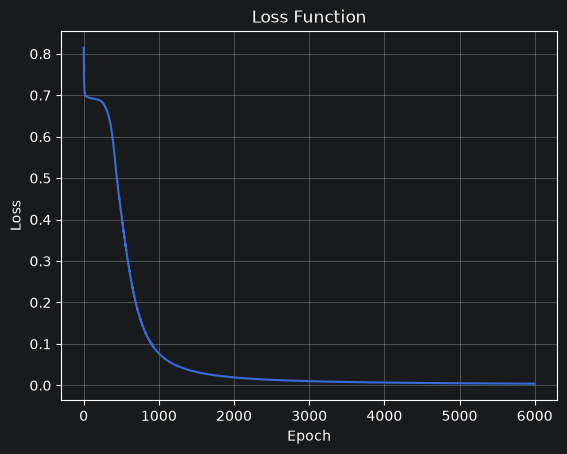

In [49]:
plt.plot(losses)
plt.title("Loss Function")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()